<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/Advanced_AI_Recruitment_Bias_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Recruitment Bias: Detection, Analysis and Mitigation
### Practical case study using Python, Pandas and Scikit-learn

**Objective:** Simulate an AI recruitment pipeline using a larger, more realistic synthetic applicant dataset; identify data and model bias; evaluate group fairness; and compare an unfair historical model with an audited mitigation model.

**Important:** All records are synthetic. This is an educational experiment, not a real hiring tool. Gender is used only for auditing and for demonstrating the biased historical process. It should not be used to disadvantage real applicants.


## Cell 1 — Import libraries and configure the experiment

We use Pandas/NumPy for data preparation, Scikit-learn for machine learning, and Matplotlib/Seaborn for visual analysis.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Environment ready.")


Environment ready.


## Cell 2 — Generate a realistic synthetic applicant population

The dataset contains 6,000 fictional applicants for software engineering roles. It includes job-related attributes (assessment, skills, experience, projects and certifications) and contextual attributes that can act as proxies (college prestige, career gap and referral access).

We separately create:
- `Qualified`: an audited job-related benchmark based on job criteria only.
- `Historical_Hired`: a simulated historical decision that contains gender and proxy-related disadvantages.

This separation is important: it lets us measure whether a model reproduces historical decisions instead of actual job-related qualification.

In [2]:
N = 6000

gender = rng.choice(["Female", "Male"], N, p=[0.42, 0.58])
age_band = rng.choice(["21-24", "25-29", "30-34", "35+"], N, p=[0.42, 0.34, 0.17, 0.07])
education = rng.choice(
    ["Bachelor", "Master", "Diploma"],
    N, p=[0.72, 0.20, 0.08]
)
college_tier = rng.choice(["Tier 1", "Tier 2", "Tier 3"], N, p=[0.18, 0.37, 0.45])
job_role = rng.choice(
    ["Backend Developer", "Frontend Developer", "Data Analyst", "ML Engineer"],
    N, p=[0.32, 0.27, 0.23, 0.18]
)

# Job-related applicant attributes
coding_score = np.clip(rng.normal(68, 15, N), 0, 100)
technical_score = np.clip(rng.normal(70, 14, N), 0, 100)
communication_score = np.clip(rng.normal(67, 13, N), 0, 100)
experience_years = np.clip(rng.gamma(shape=2.0, scale=1.7, size=N), 0, 15)
projects = np.clip(rng.poisson(2.4, N), 0, 10)
certifications = np.clip(rng.poisson(1.3, N), 0, 8)
internships = np.clip(rng.poisson(0.8, N), 0, 5)

# Contextual/proxy attributes (not valid substitutes for competence)
career_gap_months = np.clip(
    rng.gamma(1.5, 7, N) + np.where(gender == "Female", 5, 0), 0, 48
).round(0)
referral = rng.binomial(
    1, np.where(gender == "Male", 0.34, 0.22), N
)
college_bonus = np.select(
    [college_tier == "Tier 1", college_tier == "Tier 2"],
    [8, 3], default=0
)

# Audited qualification benchmark uses job-related criteria only
job_score = (
    0.30 * coding_score
    + 0.27 * technical_score
    + 0.12 * communication_score
    + 1.35 * experience_years
    + 1.25 * projects
    + 0.90 * certifications
    + 0.70 * internships
)

# Qualification is based on job-relevant score, not gender or college prestige
qualification_probability = 1 / (1 + np.exp(-(job_score - 54) / 7))
qualified = rng.binomial(1, qualification_probability)

# Historical decisions reproduce past preference patterns and proxy effects
gender_penalty = np.where(gender == "Female", 0.85, 0.0)
gap_penalty = 0.045 * career_gap_months
historical_logit = (
    (job_score - 55) / 7
    + 0.22 * (referral - 0.25)
    + 0.055 * college_bonus
    - gender_penalty
    - gap_penalty
)
historical_probability = 1 / (1 + np.exp(-historical_logit))
historical_hired = rng.binomial(1, historical_probability)

applicants = pd.DataFrame({
    "Gender": gender,
    "Age_Band": age_band,
    "Education": education,
    "College_Tier": college_tier,
    "Job_Role": job_role,
    "Coding_Score": coding_score.round(1),
    "Technical_Score": technical_score.round(1),
    "Communication_Score": communication_score.round(1),
    "Experience_Years": experience_years.round(1),
    "Projects": projects,
    "Certifications": certifications,
    "Internships": internships,
    "Career_Gap_Months": career_gap_months,
    "Referral": referral,
    "Qualified": qualified,
    "Historical_Hired": historical_hired
})

print("Dataset shape:", applicants.shape)
display(applicants.head(10))


Dataset shape: (6000, 16)


,Gender,Age_Band,Education,College_Tier,Job_Role,Coding_Score,Technical_Score,Communication_Score,Experience_Years,Projects,Certifications,Internships,Career_Gap_Months,Referral,Qualified,Historical_Hired
0,Male,25-29,Bachelor,Tier 1,Data Analyst,39.5,56.8,56.5,0.8,3,2,1,1.0,0,0,0
1,Male,21-24,Bachelor,Tier 3,Frontend Developer,55.3,69.6,47.9,3.4,1,1,4,14.0,0,0,0
2,Male,25-29,Bachelor,Tier 3,Backend Developer,53.1,62.5,70.5,1.8,2,0,2,1.0,1,0,0
3,Male,21-24,Diploma,Tier 2,Backend Developer,57.9,43.2,85.2,1.9,3,3,1,4.0,0,0,0
4,Female,21-24,Bachelor,Tier 3,Backend Developer,72.5,61.3,66.0,1.2,1,0,0,5.0,0,0,0
5,Male,25-29,Bachelor,Tier 3,Backend Developer,76.1,54.8,67.3,0.2,2,0,0,9.0,0,1,0
6,Male,25-29,Bachelor,Tier 3,Backend Developer,52.9,74.7,66.9,2.0,4,0,1,29.0,1,1,0
7,Male,30-34,Master,Tier 2,ML Engineer,56.2,47.2,70.3,2.2,2,0,0,8.0,0,0,0
8,Female,30-34,Master,Tier 1,Backend Developer,84.3,56.3,80.0,1.6,1,1,2,8.0,1,0,0
9,Male,30-34,Bachelor,Tier 1,Data Analyst,93.6,62.7,91.9,1.2,1,1,1,4.0,1,1,0


## Cell 3 — Data quality and descriptive analysis

Inspect missing values, duplicates, data types, group sizes and qualification/hiring rates. This is the first step in a responsible data audit.

In [3]:
print("Dataset dimensions:", applicants.shape)
print("\nMissing values:")
display(applicants.isna().sum().to_frame("Missing_Count"))

print("Duplicate rows:", applicants.duplicated().sum())

print("\nGender distribution:")
display(applicants["Gender"].value_counts().to_frame("Applicants"))

rates = applicants.groupby("Gender")[["Qualified", "Historical_Hired"]].mean() * 100
print("\nQualification rate vs historical hiring rate (%):")
display(rates.round(2))


Dataset dimensions: (6000, 16)

Missing values:


,Missing_Count
Gender,0
Age_Band,0
Education,0
College_Tier,0
Job_Role,0
Coding_Score,0
Technical_Score,0
Communication_Score,0
Experience_Years,0
Projects,0


Duplicate rows: 0

Gender distribution:


,Applicants
Gender,
Male,3442
Female,2558



Qualification rate vs historical hiring rate (%):


,Qualified,Historical_Hired
Gender,,
Female,55.59,27.25
Male,58.43,47.82


## Cell 4 — Visualize representation and historical outcomes

The plots show representation, qualification rates and historical hiring rates. Compare the qualification rate with the historical hiring rate: a gap can indicate that historical decisions do not reflect job-related qualification consistently.

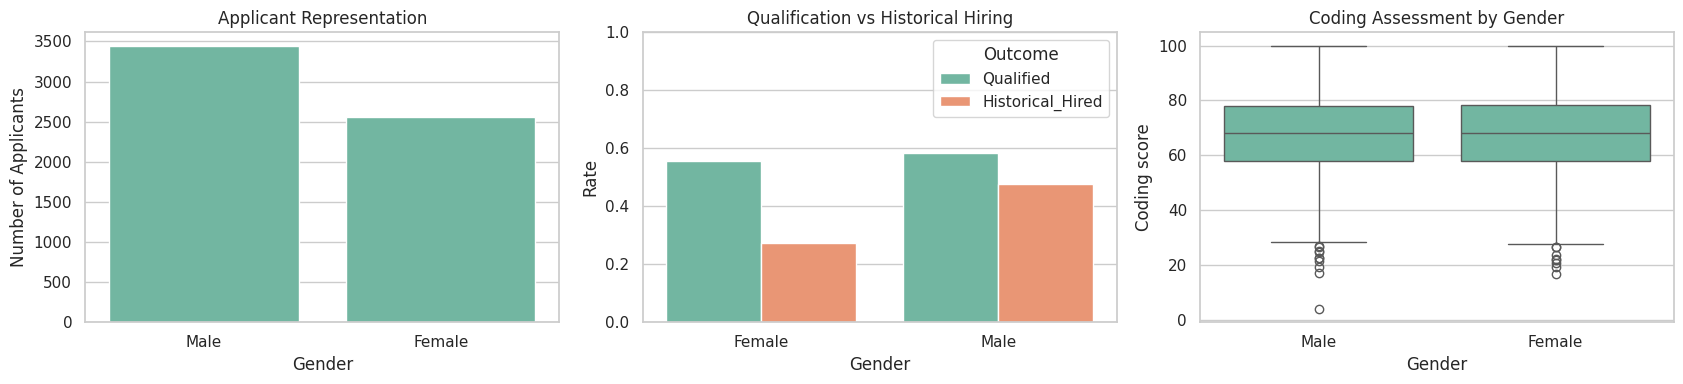

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.countplot(data=applicants, x="Gender", ax=axes[0])
axes[0].set_title("Applicant Representation")
axes[0].set_ylabel("Number of Applicants")

plot_rates = applicants.groupby("Gender")[["Qualified", "Historical_Hired"]].mean().reset_index()
plot_rates = plot_rates.melt(id_vars="Gender", var_name="Outcome", value_name="Rate")
sns.barplot(data=plot_rates, x="Gender", y="Rate", hue="Outcome", ax=axes[1])
axes[1].set_title("Qualification vs Historical Hiring")
axes[1].set_ylabel("Rate")
axes[1].set_ylim(0, 1)

sns.boxplot(data=applicants, x="Gender", y="Coding_Score", ax=axes[2])
axes[2].set_title("Coding Assessment by Gender")
axes[2].set_ylabel("Coding score")

plt.tight_layout()
plt.show()


## Cell 5 — Define fairness metrics

We calculate selection rate, true-positive rate (TPR), false-positive rate (FPR), precision and the selection-rate ratio for each gender.

- **Selection rate:** fraction of applicants predicted as selected.
- **TPR / opportunity rate:** fraction of qualified applicants correctly selected.
- **FPR:** fraction of unqualified applicants incorrectly selected.
- **Selection-rate ratio:** lower group selection rate divided by higher group selection rate.

These metrics provide different perspectives. No single metric proves that a system is fair.

In [5]:
def fairness_report(y_true, y_pred, groups, model_name):
    frame = pd.DataFrame({
        "Actual_Qualified": np.asarray(y_true),
        "Predicted_Selected": np.asarray(y_pred),
        "Gender": np.asarray(groups)
    })

    rows = []
    for group, part in frame.groupby("Gender"):
        tp = ((part.Actual_Qualified == 1) & (part.Predicted_Selected == 1)).sum()
        fn = ((part.Actual_Qualified == 1) & (part.Predicted_Selected == 0)).sum()
        fp = ((part.Actual_Qualified == 0) & (part.Predicted_Selected == 1)).sum()
        tn = ((part.Actual_Qualified == 0) & (part.Predicted_Selected == 0)).sum()

        rows.append({
            "Model": model_name,
            "Gender": group,
            "Applicants": len(part),
            "Selection_Rate": part.Predicted_Selected.mean(),
            "True_Positive_Rate": tp / (tp + fn) if (tp + fn) else 0,
            "False_Positive_Rate": fp / (fp + tn) if (fp + tn) else 0,
            "Precision": tp / (tp + fp) if (tp + fp) else 0
        })

    result = pd.DataFrame(rows)
    return result

def selection_ratio(report, metric="Selection_Rate"):
    values = report.set_index("Gender")[metric]
    return values.min() / values.max() if values.max() > 0 else np.nan

print("Fairness metric functions created.")


Fairness metric functions created.


## Cell 6 — Train a model that reproduces historical recruitment

This intentionally problematic model uses historical hiring decisions as its target and includes gender plus contextual proxy features. The purpose is to demonstrate how a model can learn past decisions, including unfair patterns.

We use a train/test split so evaluation is performed on records the model did not train on.

In [6]:
biased_features = [
    "Gender", "Age_Band", "Education", "College_Tier", "Job_Role",
    "Coding_Score", "Technical_Score", "Communication_Score",
    "Experience_Years", "Projects", "Certifications", "Internships",
    "Career_Gap_Months", "Referral"
]

X_biased = applicants[biased_features]
y_historical = applicants["Historical_Hired"]

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_biased, y_historical,
    test_size=0.25, random_state=RANDOM_STATE, stratify=y_historical
)

numeric_features = X_biased.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_biased.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_b = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

historical_model = Pipeline([
    ("preprocessor", preprocessor_b),
    ("classifier", LogisticRegression(max_iter=1500, class_weight=None))
])

historical_model.fit(X_train_b, y_train_b)
historical_predictions = historical_model.predict(X_test_b)
historical_probabilities = historical_model.predict_proba(X_test_b)[:, 1]

print("Historical-decision model trained.")
print("Accuracy:", round(accuracy_score(y_test_b, historical_predictions), 3))
print("F1 score:", round(f1_score(y_test_b, historical_predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_b, historical_probabilities), 3))


Historical-decision model trained.
Accuracy: 0.708
F1 score: 0.588
ROC-AUC: 0.758


## Cell 7 — Audit the historical model against job-related qualification

The model learned to predict `Historical_Hired`, but the audit compares its decisions with `Qualified`, our synthetic job-related benchmark. This exposes the difference between reproducing past decisions and identifying qualified candidates.

The gender field is used here only to group results for fairness auditing.

,Model,Gender,Applicants,Selection_Rate,True_Positive_Rate,False_Positive_Rate,Precision
0,Historical model,Female,656,0.125,0.188,0.050,0.817
1,Historical model,Male,844,0.469,0.601,0.274,0.765


Selection-rate ratio: 0.266
TPR ratio: 0.313


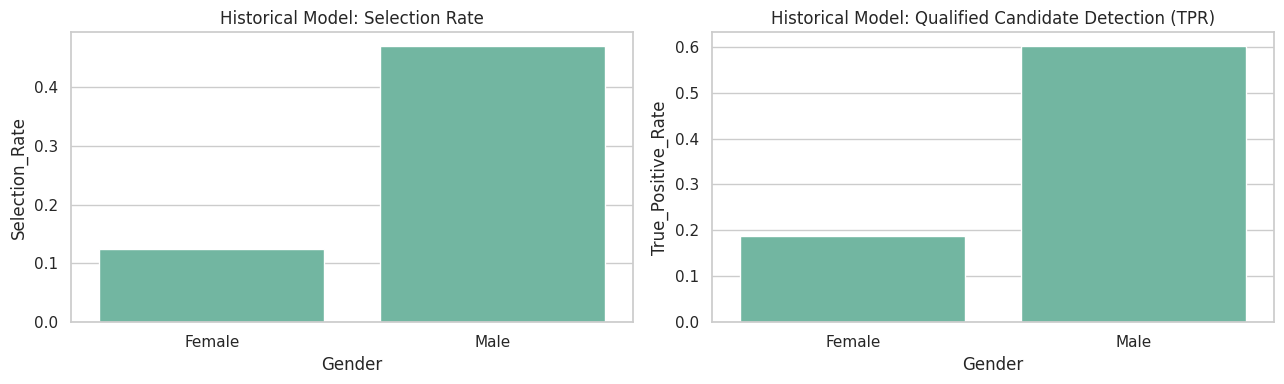

In [7]:
test_gender = applicants.loc[X_test_b.index, "Gender"].to_numpy()
test_qualified = applicants.loc[X_test_b.index, "Qualified"].to_numpy()

historical_audit = fairness_report(
    test_qualified, historical_predictions, test_gender,
    "Historical model"
)

display(historical_audit.round(3))

print("Selection-rate ratio:",
      round(selection_ratio(historical_audit), 3))
print("TPR ratio:",
      round(selection_ratio(historical_audit, "True_Positive_Rate"), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=historical_audit, x="Gender", y="Selection_Rate", ax=axes[0])
axes[0].set_title("Historical Model: Selection Rate")
sns.barplot(data=historical_audit, x="Gender", y="True_Positive_Rate", ax=axes[1])
axes[1].set_title("Historical Model: Qualified Candidate Detection (TPR)")
plt.tight_layout()
plt.show()


## Cell 8 — Inspect model errors and feature influence

A confusion matrix shows the model's classification errors against historical decisions. The logistic-regression coefficients show which encoded inputs influence the historical prediction. Coefficients are associations learned by the model, not proof of causation.

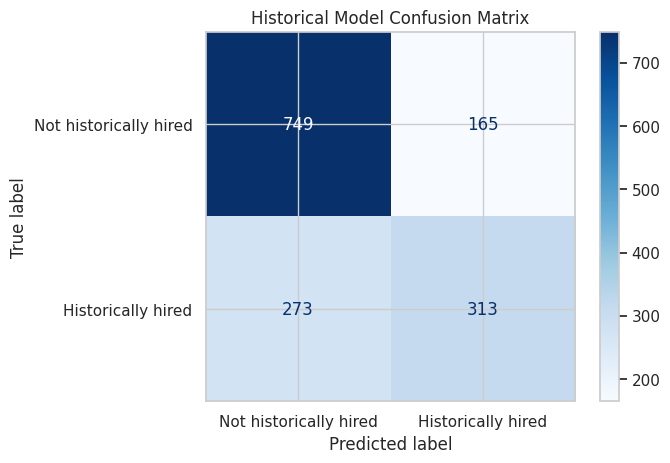

,Feature,Coefficient,Absolute_Influence
0,numeric__Coding_Score,0.666,0.666
9,categorical__Gender_Female,-0.564,0.564
1,numeric__Technical_Score,0.477,0.477
3,numeric__Experience_Years,0.458,0.458
7,numeric__Career_Gap_Months,-0.449,0.449
20,categorical__College_Tier_Tier 3,-0.339,0.339
10,categorical__Gender_Male,0.327,0.327
4,numeric__Projects,0.210,0.210
2,numeric__Communication_Score,0.210,0.210
18,categorical__College_Tier_Tier 1,0.200,0.200


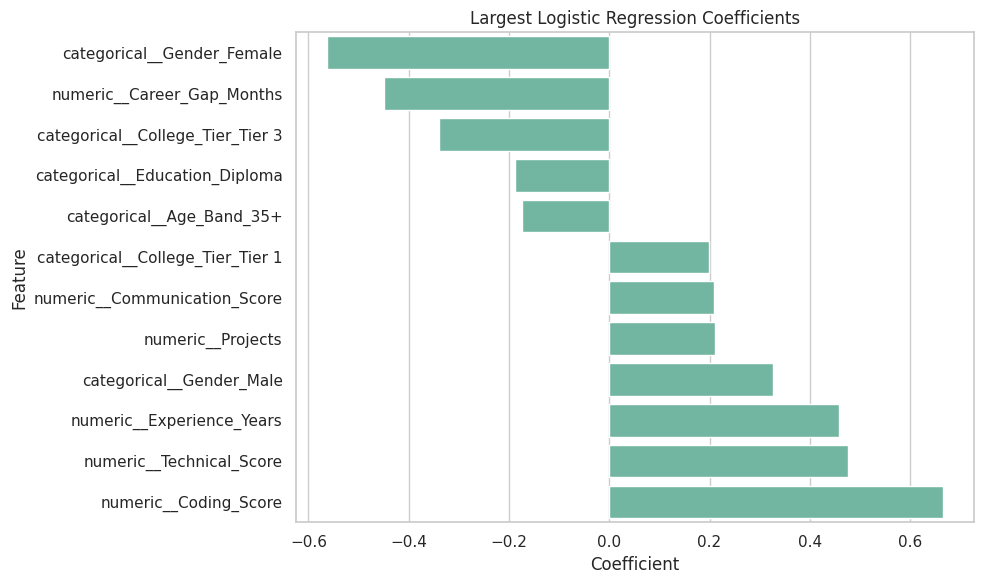

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test_b, historical_predictions,
    display_labels=["Not historically hired", "Historically hired"],
    cmap="Blues"
)
plt.title("Historical Model Confusion Matrix")
plt.show()

feature_names = historical_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = historical_model.named_steps["classifier"].coef_[0]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Influence": np.abs(coefficients)
}).sort_values("Absolute_Influence", ascending=False)

display(importance.head(15).round(3))

plt.figure(figsize=(10, 6))
top = importance.head(12).sort_values("Coefficient")
sns.barplot(data=top, x="Coefficient", y="Feature")
plt.title("Largest Logistic Regression Coefficients")
plt.tight_layout()
plt.show()


## Cell 9 — Build an audited mitigation model

For the mitigation experiment, we do not train on the historical hiring outcome. Instead, we train on the audited job-related qualification benchmark and use only job-relevant candidate attributes. Gender and contextual proxy fields are excluded from prediction inputs.

This represents a process correction: review and correct biased historical labels, define job-related criteria, and prevent protected attributes from being used in scoring. In real deployments, labels must be validated by domain experts and the fairness of remaining features must still be tested.

In [9]:
fair_features = [
    "Job_Role", "Coding_Score", "Technical_Score",
    "Communication_Score", "Experience_Years",
    "Projects", "Certifications", "Internships"
]

X_fair = applicants[fair_features]
y_qualified = applicants["Qualified"]

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_fair, y_qualified,
    test_size=0.25, random_state=RANDOM_STATE, stratify=y_qualified
)

numeric_fair = X_fair.select_dtypes(include=np.number).columns.tolist()
categorical_fair = X_fair.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_f = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_fair),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_fair)
])

mitigated_model = Pipeline([
    ("preprocessor", preprocessor_f),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced"))
])

mitigated_model.fit(X_train_f, y_train_f)
mitigated_predictions = mitigated_model.predict(X_test_f)
mitigated_probabilities = mitigated_model.predict_proba(X_test_f)[:, 1]

print("Audited mitigation model trained.")
print("Accuracy:", round(accuracy_score(y_test_f, mitigated_predictions), 3))
print("F1 score:", round(f1_score(y_test_f, mitigated_predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_f, mitigated_probabilities), 3))


Audited mitigation model trained.
Accuracy: 0.691
F1 score: 0.719
ROC-AUC: 0.758


## Cell 10 — Compare fairness before and after mitigation

Both models are evaluated against the same held-out applicant records and the same `Qualified` benchmark. This is a more meaningful comparison than comparing their accuracy against different targets.

The historical model predicts past hiring decisions; the mitigation model predicts the audited qualification benchmark. Therefore, interpret this as a comparison of the old decision process with a corrected, job-related process—not as a controlled comparison of two models trained on identical labels.

,Model,Gender,Applicants,Selection_Rate,True_Positive_Rate,False_Positive_Rate,Precision
0,Before: historical process,Female,648,0.145,0.225,0.042,0.872
1,Before: historical process,Male,852,0.461,0.613,0.253,0.768
2,After: audited process,Female,648,0.535,0.682,0.346,0.718
3,After: audited process,Male,852,0.522,0.698,0.281,0.773


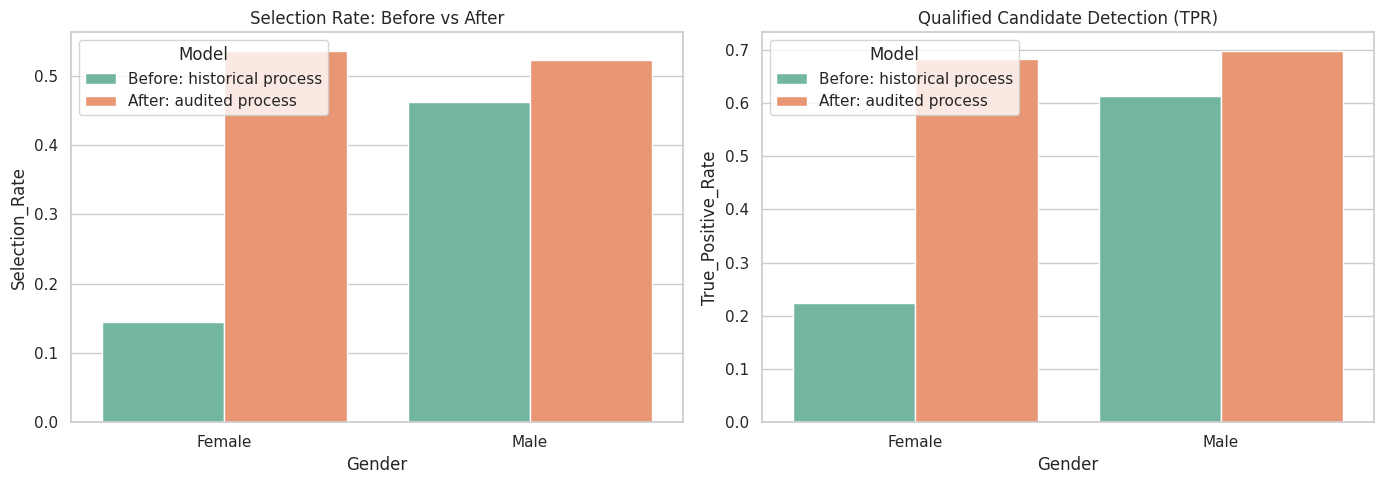

In [10]:
# The test split uses the same random state and fraction, so indices align.
# Explicitly align audit records to the mitigation test indices.
audit_indices = X_test_f.index

before_predictions = historical_model.predict(applicants.loc[audit_indices, biased_features])
after_predictions = mitigated_model.predict(X_test_f)

audit_gender = applicants.loc[audit_indices, "Gender"].to_numpy()
audit_qualified = applicants.loc[audit_indices, "Qualified"].to_numpy()

before_report = fairness_report(
    audit_qualified, before_predictions, audit_gender, "Before: historical process"
)
after_report = fairness_report(
    audit_qualified, after_predictions, audit_gender, "After: audited process"
)

combined_fairness = pd.concat([before_report, after_report], ignore_index=True)
display(combined_fairness.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=combined_fairness, x="Gender", y="Selection_Rate",
    hue="Model", ax=axes[0]
)
axes[0].set_title("Selection Rate: Before vs After")
sns.barplot(
    data=combined_fairness, x="Gender", y="True_Positive_Rate",
    hue="Model", ax=axes[1]
)
axes[1].set_title("Qualified Candidate Detection (TPR)")
plt.tight_layout()
plt.show()


## Cell 11 — Calculate and interpret selection-rate ratios

A selection-rate ratio closer to 1 means the two groups have more similar selection rates. The commonly referenced 0.80 (80%) rule is a screening convention in some settings, not a universal legal test or proof of fairness. Always examine job relevance, sample size, uncertainty, and multiple fairness metrics.

In [11]:
for report, label in [
    (before_report, "Before mitigation"),
    (after_report, "After mitigation")
]:
    sr = selection_ratio(report, "Selection_Rate")
    tpr = selection_ratio(report, "True_Positive_Rate")
    fpr = selection_ratio(report, "False_Positive_Rate")

    print(label)
    print("  Selection-rate ratio:", round(sr, 3))
    print("  TPR ratio:", round(tpr, 3))
    print("  FPR ratio:", round(fpr, 3))


Before mitigation
  Selection-rate ratio: 0.314
  TPR ratio: 0.367
  FPR ratio: 0.167
After mitigation
  Selection-rate ratio: 0.975
  TPR ratio: 0.978
  FPR ratio: 0.812


## Cell 12 — Export results

Save the synthetic dataset and fairness audit tables for your assignment report.

In [12]:
applicants.to_csv("AI_Recruitment_Synthetic_Dataset.csv", index=False)
combined_fairness.to_csv("AI_Recruitment_Fairness_Audit.csv", index=False)
importance.to_csv("Historical_Model_Feature_Coefficients.csv", index=False)

print("Export completed:")
print("1. AI_Recruitment_Synthetic_Dataset.csv")
print("2. AI_Recruitment_Fairness_Audit.csv")
print("3. Historical_Model_Feature_Coefficients.csv")


Export completed:
1. AI_Recruitment_Synthetic_Dataset.csv
2. AI_Recruitment_Fairness_Audit.csv
3. Historical_Model_Feature_Coefficients.csv


## Final observations and conclusion

### Findings to discuss
1. Historical hiring outcomes were deliberately generated with a gender penalty and proxy-related disadvantages.
2. The first model learned to reproduce the historical hiring pattern.
3. The audit compared model selections with a job-related qualification benchmark and measured group differences.
4. The mitigation experiment used reviewed qualification labels and job-related features only.
5. Fairness was assessed using selection rate, true-positive rate and false-positive rate rather than accuracy alone.

### Limitations
- The data is synthetic and cannot establish what happens in a real company.
- The qualification benchmark is simulated and would need expert validation in a real recruitment process.
- Removing gender does not remove proxy discrimination automatically.
- Similar selection rates do not guarantee equal treatment or fairness on every relevant dimension.
- Real systems need legal review, candidate recourse, human oversight, privacy controls and ongoing monitoring.

### Conclusion
AI recruitment systems can reproduce historical discrimination when trained on biased hiring records. Responsible AI requires high-quality and job-relevant data, validated labels, fairness audits, transparency, accountability and meaningful human oversight. The experiment demonstrates why model accuracy alone is insufficient to evaluate a recruitment system.
